# 보팅 앙상블

단일 모델을 앙상블하여 더 나은 예측을 하는 앙상블 모델을 만들어 보도록 하자.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
set_config(display="text")

from sklearn import datasets
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC 
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 손글씨 데이터 로드

In [2]:
mnist = datasets.load_digits()
fetures, labels = mnist.data, mnist.target

x_train, x_test, y_train, y_test = train_test_split(fetures, labels, test_size=0.2)

# 단일 모델 정확도 측정

의사결정트리, knn, svm 모델의 정확도를 측정

In [3]:
dtree = DecisionTreeClassifier(criterion='gini', max_depth=8, max_features=32
                               , random_state=100).fit(x_train, y_train)

dtree_predicted = dtree.predict(x_test) # 예측
dtree_predicted

array([2, 5, 6, 6, 0, 8, 3, 6, 1, 7, 3, 6, 9, 0, 0, 7, 7, 1, 5, 7, 5, 1,
       5, 2, 9, 1, 7, 5, 0, 6, 5, 3, 5, 1, 8, 8, 7, 3, 5, 7, 3, 2, 4, 9,
       6, 9, 5, 5, 7, 8, 4, 6, 8, 0, 7, 8, 6, 6, 0, 9, 9, 4, 8, 3, 1, 1,
       6, 0, 0, 7, 4, 2, 4, 3, 4, 7, 2, 6, 6, 3, 7, 6, 7, 6, 3, 5, 6, 5,
       9, 5, 9, 9, 0, 6, 9, 8, 0, 9, 3, 5, 8, 4, 2, 5, 5, 8, 7, 3, 2, 0,
       9, 3, 4, 4, 3, 3, 6, 0, 4, 5, 7, 5, 2, 0, 9, 9, 6, 1, 6, 3, 8, 2,
       7, 9, 5, 7, 2, 7, 8, 6, 0, 2, 7, 3, 2, 7, 0, 7, 0, 5, 3, 1, 8, 4,
       6, 4, 6, 4, 9, 3, 7, 8, 9, 8, 5, 2, 1, 3, 3, 7, 6, 8, 7, 6, 6, 9,
       5, 6, 7, 5, 1, 5, 4, 0, 5, 9, 2, 7, 6, 3, 0, 2, 9, 9, 1, 4, 0, 0,
       0, 3, 2, 0, 4, 4, 2, 3, 0, 4, 8, 1, 3, 2, 7, 0, 2, 2, 3, 6, 3, 2,
       6, 8, 9, 9, 9, 9, 1, 7, 2, 3, 7, 9, 2, 7, 2, 6, 3, 0, 3, 6, 5, 1,
       6, 3, 9, 3, 0, 4, 7, 9, 7, 8, 9, 1, 5, 3, 3, 2, 6, 7, 8, 5, 9, 8,
       6, 1, 8, 1, 2, 6, 8, 2, 2, 5, 8, 0, 3, 9, 1, 7, 4, 3, 1, 1, 3, 1,
       9, 2, 3, 2, 5, 4, 9, 7, 4, 4, 9, 9, 5, 3, 5,

In [6]:
knn = KNeighborsClassifier(n_neighbors=299).fit(x_train, y_train)
knn_predicted = knn.predict(x_test)
knn_predicted

array([2, 7, 6, 6, 0, 8, 0, 6, 1, 7, 3, 6, 9, 0, 0, 7, 1, 1, 5, 7, 5, 1,
       5, 2, 9, 9, 7, 3, 0, 6, 5, 3, 5, 1, 8, 8, 5, 7, 2, 7, 5, 2, 4, 9,
       6, 7, 0, 9, 4, 8, 4, 6, 8, 0, 9, 8, 6, 6, 0, 9, 9, 7, 8, 3, 1, 8,
       6, 0, 0, 7, 7, 2, 4, 3, 6, 7, 2, 6, 6, 3, 7, 9, 7, 9, 3, 5, 9, 5,
       9, 5, 9, 9, 0, 6, 0, 8, 0, 7, 3, 9, 8, 4, 2, 5, 5, 8, 7, 3, 2, 0,
       9, 1, 4, 4, 3, 3, 6, 0, 4, 5, 1, 5, 2, 0, 9, 9, 6, 1, 4, 3, 6, 2,
       7, 9, 9, 8, 8, 7, 8, 6, 0, 2, 7, 3, 2, 7, 0, 7, 9, 5, 3, 1, 8, 4,
       6, 4, 6, 7, 3, 9, 7, 9, 7, 8, 5, 8, 2, 8, 3, 7, 6, 8, 3, 5, 6, 9,
       5, 6, 7, 5, 1, 5, 7, 0, 5, 9, 2, 7, 4, 3, 0, 2, 9, 9, 1, 4, 0, 0,
       0, 3, 2, 0, 4, 4, 2, 3, 0, 4, 8, 1, 3, 2, 7, 0, 5, 2, 3, 6, 7, 5,
       6, 8, 9, 9, 9, 3, 1, 7, 2, 7, 8, 9, 2, 2, 2, 6, 3, 0, 3, 6, 5, 6,
       6, 9, 9, 3, 0, 4, 7, 9, 7, 8, 9, 2, 5, 3, 8, 2, 6, 8, 8, 5, 9, 8,
       6, 1, 8, 6, 2, 6, 7, 2, 2, 5, 8, 5, 8, 9, 1, 7, 0, 3, 1, 2, 3, 1,
       7, 2, 3, 1, 5, 4, 9, 7, 4, 4, 9, 9, 0, 3, 9,

In [ ]:
# probability = SVC 모델은 기본적으로 속도 향상을 위해 확률 계산 기능을 비활성화(false 기본값)-> 활성화 (True)
svm = SVC(C=0.1, gamma=0.003, random_state=100, probability=True).fit(x_train, y_train)
svm_predicted = svm.predict(x_test)
svm_predicted

c:\workspaces\machine&deepLearning\src\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


array([2, 7, 6, 6, 0, 8, 5, 6, 1, 7, 3, 6, 9, 0, 0, 7, 4, 1, 5, 7, 5, 1,
       5, 2, 2, 1, 5, 5, 0, 6, 5, 3, 5, 1, 8, 8, 5, 5, 8, 7, 5, 2, 4, 9,
       6, 7, 5, 9, 4, 8, 4, 6, 8, 0, 1, 8, 6, 6, 0, 9, 9, 7, 8, 2, 1, 1,
       5, 0, 0, 7, 7, 2, 4, 3, 4, 7, 2, 6, 6, 3, 5, 5, 7, 5, 3, 5, 8, 5,
       8, 5, 9, 9, 0, 6, 8, 5, 0, 7, 3, 5, 8, 4, 2, 5, 5, 8, 7, 3, 2, 0,
       9, 1, 4, 4, 3, 3, 6, 0, 4, 5, 4, 5, 2, 0, 9, 1, 6, 1, 4, 3, 8, 2,
       5, 5, 5, 1, 8, 7, 8, 6, 0, 2, 7, 3, 2, 7, 0, 7, 5, 5, 3, 1, 8, 4,
       6, 4, 6, 5, 9, 9, 7, 9, 4, 8, 5, 8, 1, 8, 1, 7, 6, 8, 2, 5, 6, 5,
       5, 6, 7, 5, 1, 5, 7, 0, 5, 1, 2, 7, 4, 3, 0, 2, 9, 9, 1, 4, 0, 5,
       0, 3, 2, 0, 4, 4, 2, 3, 0, 4, 8, 1, 3, 2, 5, 0, 5, 2, 3, 6, 8, 5,
       6, 8, 9, 9, 9, 3, 1, 5, 2, 8, 5, 9, 2, 5, 2, 6, 3, 0, 3, 6, 5, 1,
       6, 3, 9, 3, 5, 4, 7, 9, 7, 8, 9, 1, 5, 3, 8, 2, 6, 5, 8, 5, 9, 8,
       6, 1, 8, 1, 2, 6, 5, 2, 8, 5, 8, 5, 8, 9, 1, 7, 0, 3, 1, 1, 3, 1,
       7, 2, 3, 1, 5, 4, 8, 7, 4, 4, 9, 9, 5, 2, 5,

In [21]:
print("[accuarcy]")
print('d_tree : ', accuracy_score(y_test, dtree_predicted))
print('knn : ', accuracy_score(y_test, knn_predicted))
print('svm : ', accuracy_score(y_test, svm_predicted))

[accuarcy]
d_tree :  0.8222222222222222
knn :  0.8611111111111112
svm :  0.9


### 소프트 보팅 또는 하드 보팅은 sklearn의 voting classifier를 사용하여 쉽게 구현할 수 있다.

In [ ]:
svm_proba = svm.predict_proba(x_test)
print(svm_proba[0:2]) # 인덱스값 0서부터

[[0.00359258 0.01914683 0.85772616 0.00885215 0.00825096 0.01808578
  0.0060148  0.01769068 0.04316678 0.01747327]
 [0.00251029 0.00646468 0.00563347 0.0058328  0.00485095 0.01032366
  0.00283599 0.90628336 0.04559186 0.00967295]]


In [28]:
dtree_proba = dtree.predict_proba(x_test)
print(dtree_proba[0:2])

[[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]]


# 하드 보팅  

하드 보팅은 일반적인 투표와 같이, 각각의 분류기의 예측값들을 모아, 가장 많은 득표를 받은 예측값으로 최종 결론을 내는 방식.

In [40]:
voting_clf = VotingClassifier(estimators=[('knn', knn)
                            , ('svm', svm)
                            , ('decision_tree', dtree)]
                            , weights = [1,1,1]
                            , voting  = 'hard').fit(x_train, y_train) # voring = hard or soft

hard_voting_predicted = voting_clf.predict(x_test) # 정확도

c:\workspaces\machine&deepLearning\src\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [41]:
accuracy_score(y_test, hard_voting_predicted)

0.8944444444444445

# 소프트 보팅

소프트 보팅은 각각의 분류 모델의 predict_proba()을 활용하여, 모든 분류값들의 확률들을 더해서, 가장 높은 점수를 획득한 분류값으로 최종 결론을 내는 방식.

In [43]:
voting_clf = VotingClassifier(estimators=[('knn', knn)
                            , ('svm', svm)
                            , ('decision_tree', dtree)]
                            , weights = [1,1,1]
                            , voting  = 'soft').fit(x_train, y_train) # voring = hard or soft

soft_voting_predicted = voting_clf.predict(x_test) # 정확도

c:\workspaces\machine&deepLearning\src\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [44]:
accuracy_score(y_test, soft_voting_predicted)

0.8777777777777778

# 정확도 비교 시각화

([<matplotlib.axis.XTick at 0x1c7ba833fe0>,
 [Text(0, 0, 'decision_tree'),
  Text(1, 0, 'knn'),
  Text(2, 0, 'svm'),
  Text(3, 0, 'hard_voting'),
  Text(4, 0, 'soft_voting')])

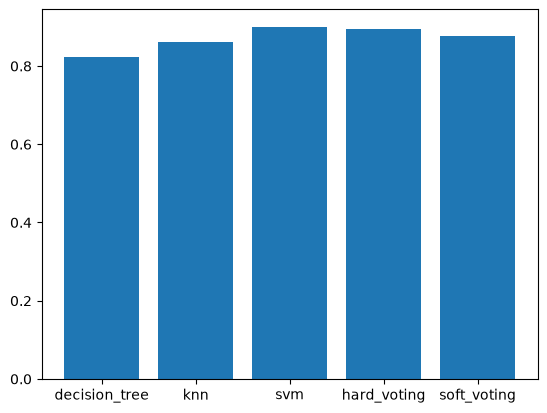

In [52]:
x = np.arange(5)
plt.bar(x, height=[
   accuracy_score(y_test, dtree_predicted)
 , accuracy_score(y_test, knn_predicted)
 , accuracy_score(y_test, svm_predicted)
 , accuracy_score(y_test, hard_voting_predicted)
 , accuracy_score(y_test, soft_voting_predicted)
])

plt.xticks(x,['decision_tree', 'knn', 'svm', 'hard_voting', 'soft_voting'])